# 01 - Análisis Exploratorio de Datos (EDA)

En este notebook hacemos una primera exploración de los datos **RAW** (tal como los descargamos, sin modificar).

**¿Qué buscamos?**
- Ver cómo están distribuidos los datos y en qué rangos de valores se mueven.
- Detectar problemas básicos (nulos, duplicados, formatos raros).
- Dejar anotado qué debemos **preprocesar** antes de entrenar y cómo vamos a **cruzar** las fuentes.

**Secciones:**
1. Contratos
2. Convocatorias
3. Entidades contratantes
4. Sancionados (inhabilitaciones)
5. Sancionados con multa
6. RNP (Tribunal de Contrataciones)
7. Relación entre las fuentes
8. Resumen de preprocesamiento

## 0. Preparación

In [2]:
from pathlib import Path
import re, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Ruta relativa: funciona si el notebook está en proyecto/ o en proyecto/notebooks/
RAIZ = Path('..') if (Path('..') / 'data' / 'raw').exists() else Path('.')
RAW = RAIZ / 'data' / 'raw'
RAW

WindowsPath('../data/raw')

### Archivos por año: ¿podemos leer solo uno?

Contratos y convocatorias vienen en un archivo por año (2023 a 2026). Antes de leer solo uno, revisamos que todos tengan las mismas columnas (leemos solo los encabezados, así es rápido).

In [3]:
def columnas_por_archivo(carpeta):
    # Solo leemos el encabezado (nrows=0) y pasamos los nombres a minúscula
    return {f.name: [c.lower() for c in pd.read_excel(f, nrows=0).columns]
            for f in sorted((RAW / carpeta).glob('*.xlsx'))}

for carpeta in ['contratos', 'convocatorias']:
    cols = columnas_por_archivo(carpeta)
    base = list(cols.values())[0]
    for nombre, c in cols.items():
        dif = set(c) ^ set(base)
        print(f'{nombre:35s} igual al primero: {c == base} | diferencias: {dif if dif else "-"}')

CONOSCE_CONTRATOS2023_0.xlsx        igual al primero: True | diferencias: -
CONOSCE_CONTRATOS2024_0.xlsx        igual al primero: True | diferencias: -
CONOSCE_CONTRATOS2025_0.xlsx        igual al primero: True | diferencias: -
CONOSCE_CONTRATOS2026_0.xlsx        igual al primero: True | diferencias: -
CONOSCE_CONVOCATORIAS2023_0.xlsx    igual al primero: True | diferencias: -
CONOSCE_CONVOCATORIAS2024_0.xlsx    igual al primero: True | diferencias: -
CONOSCE_CONVOCATORIAS2025_0.xlsx    igual al primero: False | diferencias: {'col_10', 'sector / nivel de gobierno'}
CONOSCE_CONVOCATORIAS2026_0.xlsx    igual al primero: True | diferencias: -


Lo que vimos:
- Las columnas son las mismas en todos los años, pero en **2025 y 2026 los nombres vienen en MAYÚSCULAS** (en 2023 y 2024 vienen en minúscula).
- En **convocatorias 2025** la columna `SECTOR / NIVEL DE GOBIERNO` aparece con el nombre `COL_10`.

Por eso, para el EDA leemos **un solo año (2024)**, que es un año completo y con los nombres en minúscula. En el preprocesamiento tendremos que unificar los nombres de columnas antes de juntar los años.

## 1. Contratos

In [4]:
contratos = pd.read_excel(RAW / 'contratos' / 'CONOSCE_CONTRATOS2024_0.xlsx')
print(contratos.shape)
contratos.head()

(11170, 24)


,codigoentidad,codigoconvocatoria,descripcion_proceso,n_cod_contrato,codigo_contrato,num_contrato,num_item,monto_contratado_total,monto_contratado_item,monto_adicional,monto_reduccion,monto_prorroga,monto_complementario,moneda,ruc_contratista,ruc_destinatario_pago,tieneresolucion,urlcontrato,espublicado,fecha_publicacion_contrato,fecha_suscripcion_contrato,fecha_vigencia_inicial,fecha_vigencia_final,fecha_vigencia_fin_actualizada
0,10006,998099,SERVICIO DE ALQUILER DE DE UN INMUEBLE PARA EL...,2244522,2244522,1-2024,1,"56,000.00","56,000.00",0.00,0.00,"98,000.00",0,Soles,10157231150,10157231150,NaN,https://prodapp2.seace.gob.pe/portalseace-uiwd...,1,2024-03-26,2024-03-22,2024-03-22,2024-10-31,2024-10-31
1,203766,1012439,SERVICIO DE ALQUILER DE LOCAL PARA LAS OFICINA...,2257726,2257726,CONTRATO N°63-2024-DIRIS-LS,1,"999,693.96","999,693.96",0.00,0.00,"83,307.83",0,Soles,20144154241,20144154241,NaN,https://prodapp2.seace.gob.pe/portalseace-uiwd...,1,2024-06-10,2024-05-29,2024-05-29,2025-05-29,2025-05-29
2,204387,1078872,SERVICIO DE ALQUILER DE ALMACEN UBICADO EN LA ...,2304401,2304401,CONTRATO N 028-2024-MTC/24.07,1,"927,291.20","927,291.20",0.00,0.00,"92,729.12",0,Soles,20521218097,20521218097,NaN,https://prodapp2.seace.gob.pe/portalseace-uiwd...,1,2025-01-22,2024-12-19,2025-01-08,2025-10-04,2025-10-04
3,1920,1012872,Contratación del servicio de arrendamiento de ...,2253716,2253716,60-2024,1,"144,000.00","144,000.00",0.00,0.00,"72,000.00",0,Soles,10026167553,10026167553,NaN,https://prodapp2.seace.gob.pe/portalseace-uiwd...,1,2024-05-14,2024-05-13,2024-05-14,2026-05-14,2026-05-14
4,200363,1080436,SERVICIO DE ALQUILER DE ALMACÉN COMPLEMENTARIO...,2304088,2304088,0018-2025-CENARES/MINSA,1,"100,890.00","100,890.00",0.00,0.00,"100,890.00",0,Soles,20492093042,20492093042,NaN,https://prodapp2.seace.gob.pe/portalseace-uiwd...,1,2025-01-13,2025-01-07,2025-01-09,2025-04-08,2025-04-08


In [5]:
contratos.info()

<class 'pandas.DataFrame'>
RangeIndex: 11170 entries, 0 to 11169
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   codigoentidad                   11170 non-null  int64         
 1   codigoconvocatoria              11170 non-null  int64         
 2   descripcion_proceso             11170 non-null  str           
 3   n_cod_contrato                  11170 non-null  int64         
 4   codigo_contrato                 11170 non-null  int64         
 5   num_contrato                    11170 non-null  str           
 6   num_item                        11170 non-null  int64         
 7   monto_contratado_total          11170 non-null  float64       
 8   monto_contratado_item           11170 non-null  float64       
 9   monto_adicional                 11170 non-null  float64       
 10  monto_reduccion                 11170 non-null  float64       
 11  monto_prorrog

Columnas principales:
- **Llaves:** `codigoentidad` (entidad), `codigoconvocatoria` (proceso), `codigo_contrato`, `num_item`, `ruc_contratista` (proveedor).
- **Montos:** `monto_contratado_item`, `monto_contratado_total`, y los montos de modificaciones (`monto_adicional`, `monto_reduccion`, `monto_prorroga`, `monto_complementario`).
- **Fechas:** publicación, suscripción y vigencia del contrato.

In [6]:
# Columnas con valores nulos
nulos = contratos.isna().sum()
nulos[nulos > 0]

tieneresolucion    11001
dtype: int64

In [7]:
cols_monto = ['monto_contratado_total', 'monto_contratado_item', 'monto_adicional',
              'monto_reduccion', 'monto_prorroga', 'monto_complementario']
contratos[cols_monto].describe()

,monto_contratado_total,monto_contratado_item,monto_adicional,monto_reduccion,monto_prorroga,monto_complementario
count,"11,170.00","11,170.00","11,170.00","11,170.00","11,170.00","11,170.00"
mean,"6,211,917.63","5,869,147.51","132,002.71","27,604.88","3,066.99",0.00
std,"30,974,129.89","30,872,613.85","477,445.50","257,818.56","42,641.68",0.00
min,300.00,300.00,0.00,0.00,0.00,0.00
25%,"190,000.00","167,439.25",0.00,0.00,0.00,0.00
50%,"711,719.04","624,625.56","23,849.19",0.00,0.00,0.00
75%,"3,322,376.19","2,844,013.43","95,647.43",692.28,0.00,0.00
max,"806,093,923.08","806,093,923.08","16,081,238.40","16,806,065.52","2,451,138.00",0.00


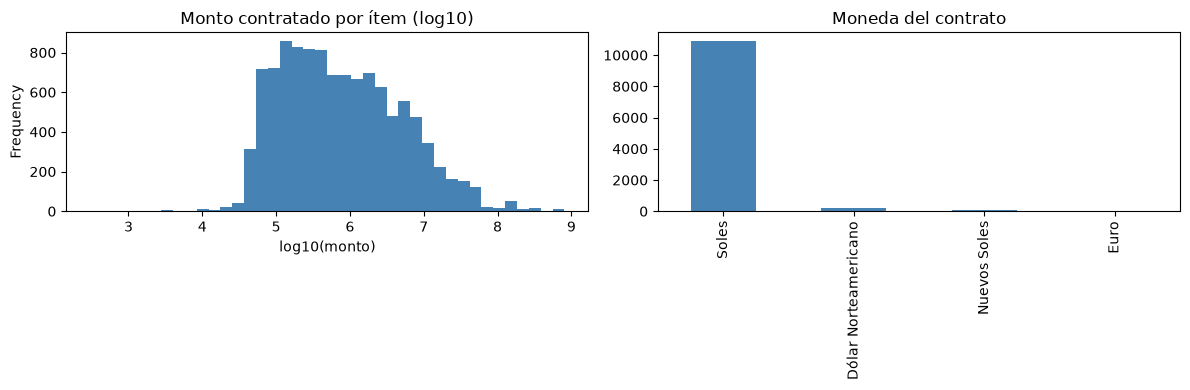

In [8]:
# Los montos son muy desiguales (hay pocos contratos enormes), por eso usamos escala logarítmica
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

np.log10(contratos['monto_contratado_item']).plot.hist(bins=40, ax=ax[0], color='steelblue')
ax[0].set_title('Monto contratado por ítem (log10)')
ax[0].set_xlabel('log10(monto)')

contratos['moneda'].value_counts().plot.bar(ax=ax[1], color='steelblue')
ax[1].set_title('Moneda del contrato')
ax[1].set_xlabel('')

plt.tight_layout()
plt.show()

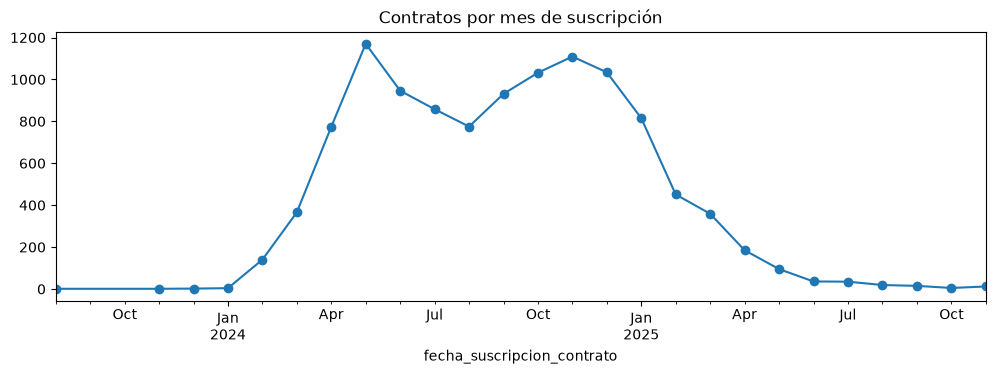

fecha_suscripcion_contrato
2023-08    1
2023-11    1
2023-12    2
Freq: M, Name: count, dtype: int64

In [9]:
# ¿Cuántos contratos hay por mes de suscripción?
por_mes = contratos['fecha_suscripcion_contrato'].dt.to_period('M').value_counts().sort_index()
por_mes.plot(figsize=(12, 3.5), marker='o', title='Contratos por mes de suscripción')
plt.show()
por_mes.head(3)

In [10]:
# Filas vs. contratos reales: un contrato puede tener varios ítems (una fila por ítem)
print('Filas:                     ', len(contratos))
print('Contratos únicos:          ', contratos['codigo_contrato'].nunique())
print('Convocatorias únicas:      ', contratos['codigoconvocatoria'].nunique())
print('Contratistas únicos (RUC): ', contratos['ruc_contratista'].nunique())
print('Entidades únicas:          ', contratos['codigoentidad'].nunique())
print('Filas duplicadas completas:', contratos.duplicated().sum())
print()
print('Ítems por fila (num_item):')
print(contratos['num_item'].value_counts().head(5))

Filas:                      11170
Contratos únicos:           7452
Convocatorias únicas:       6950
Contratistas únicos (RUC):  5715
Entidades únicas:           1400
Filas duplicadas completas: 0

Ítems por fila (num_item):
num_item
1    9816
2     474
3     230
4     132
5      82
Name: count, dtype: int64


In [11]:
# Revisamos el RUC del contratista: debería tener 11 dígitos
largo_ruc = contratos['ruc_contratista'].astype(str).str.len()
print(largo_ruc.value_counts())
print()
print('RUC contratista distinto al RUC que recibe el pago:',
      (contratos['ruc_contratista'] != contratos['ruc_destinatario_pago']).mean().round(3))
contratos.loc[largo_ruc < 11, 'ruc_contratista'].head()

ruc_contratista
11    6713
7     4452
6        5
Name: count, dtype: int64

RUC contratista distinto al RUC que recibe el pago: 0.401


37    1565736
40    1608521
44    1531219
46    1546375
48    1563100
Name: ruc_contratista, dtype: str

In [12]:
# ¿Qué tan frecuentes son las modificaciones del contrato?
mods = ['monto_adicional', 'monto_reduccion', 'monto_prorroga', 'monto_complementario']
(contratos[mods] > 0).mean().round(3)

monto_adicional        0.71
monto_reduccion        0.27
monto_prorroga         0.03
monto_complementario   0.00
dtype: float64

In [13]:
# Revisamos fechas: suscripción posterior a la publicación, y vigencia final antes de la inicial
print('Suscripción después de publicación:', (contratos['fecha_suscripcion_contrato'] > contratos['fecha_publicacion_contrato']).sum())
print('Vigencia final antes de la inicial:', (contratos['fecha_vigencia_final'] < contratos['fecha_vigencia_inicial']).sum())
contratos[['fecha_suscripcion_contrato', 'fecha_vigencia_inicial', 'fecha_vigencia_final']].agg(['min', 'max'])

Suscripción después de publicación: 39
Vigencia final antes de la inicial: 0


,fecha_suscripcion_contrato,fecha_vigencia_inicial,fecha_vigencia_final
min,2023-08-14,2023-08-14,2023-10-23
max,2025-11-12,2025-12-31,2047-12-31


### Qué vimos en contratos
- Tenemos **11,170 filas** pero solo **7,452 contratos únicos**: cada fila es un ítem, así que un mismo contrato se repite. Tenemos que definir la unidad de análisis (contrato o ítem).
- Casi no hay nulos: solo `tieneresolucion` (vacía en casi todas las filas). `espublicado` (siempre 1) y `monto_complementario` (siempre 0) son **constantes**, no aportan información.
- Los montos están muy desbalanceados: la mediana del ítem es ~625 mil, pero el promedio es ~5.9 millones y el máximo ~806 millones. Hay pocos contratos gigantes que dominan el promedio.
- Hay varias **monedas** (Soles, Nuevos Soles, Dólar, Euro). Casi todo está en Soles, pero los montos no son directamente comparables.
- **Problema con el RUC:** 4,457 filas (~40%) tienen `ruc_contratista` de 6 o 7 dígitos (parecen códigos internos, quizás de consorcios, no lo sabemos con certeza). En cambio `ruc_destinatario_pago` siempre tiene 11 dígitos.
- Las modificaciones son comunes: ~71% de las filas tienen monto adicional y ~27% tienen reducción.
- Las fechas tienen algunos valores raros: 39 contratos firmados después de su publicación y una vigencia final hasta el año 2047. Además, el archivo "2024" incluye contratos publicados hasta 2026, así que el año del archivo parece depender de la convocatoria y no de las fechas del contrato.

## 2. Convocatorias

In [14]:
convocatorias = pd.read_excel(RAW / 'convocatorias' / 'CONOSCE_CONVOCATORIAS2024_0.xlsx')
print(convocatorias.shape)
convocatorias.head()

(67291, 28)


,codigoentidad,entidad_ruc,entidad,tipoentidad,codigoconvocatoria,descripcion_proceso,proceso,tipocompra,objetocontractual,SECTOR / NIVEL DE GOBIERNO,sistema_contratacion,tipoprocesoseleccion,montoreferencial,n_item,descripcion_item,unidad_medida,estadoitem,paquete,codigoitem,itemcubso,monto_referencial_item,moneda,departamento_item,provincia_item,distrito_item,fecha_convocatoria,fechaintegracionbases,fechapresentacionpropuesta
0,2009,20527141762,GOBIERNO REGIONAL DE APURIMAC SEDE CENTRAL,GOBIERNO REGIONAL,991144,CONTRATACIÓN DEL SERVICIO DE ALQUILER DE CAMIO...,AS-SM-7-2024-GRAP-1,Por la Entidad,Servicio,GOBIERNO REGIONAL,Precios unitarios,Adjudicación Simplificada,"411,495.00",1,CONTRATACIÓN DEL SERVICIO DE ALQUILER DE CAMIO...,Servicio,Contratado,NO,"232,926.00",SERVICIO DE ALQUILER DE CAMIONETA,"411,495.00",Soles,APURIMAC,ANDAHUAYLAS,SAN JERONIMO,2024-02-28,2024-03-04,2024-03-07
1,49,20406325815,GOBIERNO REGIONAL DE PUNO SEDE CENTRAL,GOBIERNO REGIONAL,1054852,ADQUISICION DE BARRAS PARA CONSTRUCCION GRADO ...,SIE-SIE-165-2024-OEC/GR PUNO-1,Por la Entidad,Bien,GOBIERNO REGIONAL,Suma alzada,Subasta Inversa Electrónica,"359,285.10",1,ADQUISICION DE BARRAS PARA COSNTRUCCION GRADO ...,Unidad,Contratado,SI,NaN,NaN,"359,285.10",Soles,PUNO,PUNO,ACORA,2024-09-24,NaT,2024-09-25
2,10471,20171178585,GOBIERNO REGIONAL DE ICA-SALUD,GOBIERNO REGIONAL,1027905,Mantenimiento de la Infraestructura del establ...,AS-SM-6-2024-DIRESA-ICA-OEC-1,Por la Entidad,Servicio,GOBIERNO REGIONAL,Suma alzada,Adjudicación Simplificada,"58,139.34",1,Mantenimiento de la Infraestructura del establ...,Servicio,Contratado,NO,"341,204.00",SERVICIO DE MANTENIMIENTO DE INFRAESTRUCTURA D...,"58,139.34",Soles,ICA,ICA,ICA,2024-06-24,2024-07-04,2024-07-09
3,1591,20147034467,MUNICIPALIDAD DISTRITAL DE LAS LOMAS,GOBIERNO LOCAL,995548,CONTRATACION DEL SERVICIO DE CONSULTORIA DE OB...,AS-SM-4-2024-MDLL-CS-1,Por la Entidad,Consultoría de Obra,GOBIERNO LOCAL,Suma alzada,Adjudicación Simplificada,"97,940.00",1,CONTRATACION DEL SERVICIO DE CONSULTORIA DE OB...,Servicio,Contratado,NO,"226,836.00",ELABORACION DE EXPEDIENTE TECNICO DE OBRA PARA...,"97,940.00",Soles,PIURA,PIURA,LAS LOMAS,2024-03-13,2024-04-01,2024-04-04
4,1793,20154544667,MUNICIPALIDAD PROVINCIAL DE SAN MARTIN - TARAPOTO,GOBIERNO LOCAL,1086489,EJECUCION DE OBRA: ¿CONSTRUCCIÓN DE PAVIMENTO;...,AS-SM-20-2024-MPSM/CS-1,Por la Entidad,Obra,GOBIERNO LOCAL,Precios unitarios,Adjudicación Simplificada,"788,833.75",1,EJECUCION DE OBRA: ¿CONSTRUCCIÓN DE PAVIMENTO;...,Servicio,Contratado,NO,"233,103.00",CONSTRUCCION DE CALLES CON PAVIMENTO,"788,833.75",Soles,SAN MARTIN,SAN MARTIN,TARAPOTO,2024-12-19,NaT,NaT


In [15]:
convocatorias.info()

<class 'pandas.DataFrame'>
RangeIndex: 67291 entries, 0 to 67290
Data columns (total 28 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   codigoentidad               67291 non-null  int64         
 1   entidad_ruc                 67291 non-null  int64         
 2   entidad                     67291 non-null  str           
 3   tipoentidad                 67291 non-null  str           
 4   codigoconvocatoria          67291 non-null  int64         
 5   descripcion_proceso         67291 non-null  str           
 6   proceso                     67291 non-null  str           
 7   tipocompra                  67291 non-null  str           
 8   objetocontractual           67291 non-null  str           
 9   SECTOR / NIVEL DE GOBIERNO  67291 non-null  str           
 10  sistema_contratacion        67289 non-null  str           
 11  tipoprocesoseleccion        67291 non-null  str           
 12  m

Columnas principales:
- **Llaves:** `codigoentidad`, `entidad_ruc`, `codigoconvocatoria`, `n_item`.
- **Categóricas:** tipo de entidad, objeto contractual (bien, servicio, obra...), tipo de proceso de selección, sistema de contratación, estado del ítem.
- **Montos:** `montoreferencial` (del proceso) y `monto_referencial_item`.
- **Ubicación:** departamento, provincia y distrito del ítem.
- **Fechas:** convocatoria, integración de bases y presentación de propuestas.

In [16]:
nulos = convocatorias.isna().sum()
nulos[nulos > 0]

sistema_contratacion              2
codigoitem                    10576
itemcubso                     10576
departamento_item               508
provincia_item                  508
distrito_item                   508
fechaintegracionbases         24507
fechapresentacionpropuesta     7363
dtype: int64

In [17]:
convocatorias[['montoreferencial', 'monto_referencial_item']].describe()

,montoreferencial,monto_referencial_item
count,"67,291.00","67,291.00"
mean,"2,010,885.69","1,135,322.27"
std,"12,837,598.96","10,571,197.71"
min,0.00,0.00
25%,"89,052.71","78,968.99"
50%,"203,614.93","167,040.00"
75%,"574,801.39","428,020.58"
max,"839,816,887.41","839,816,887.41"


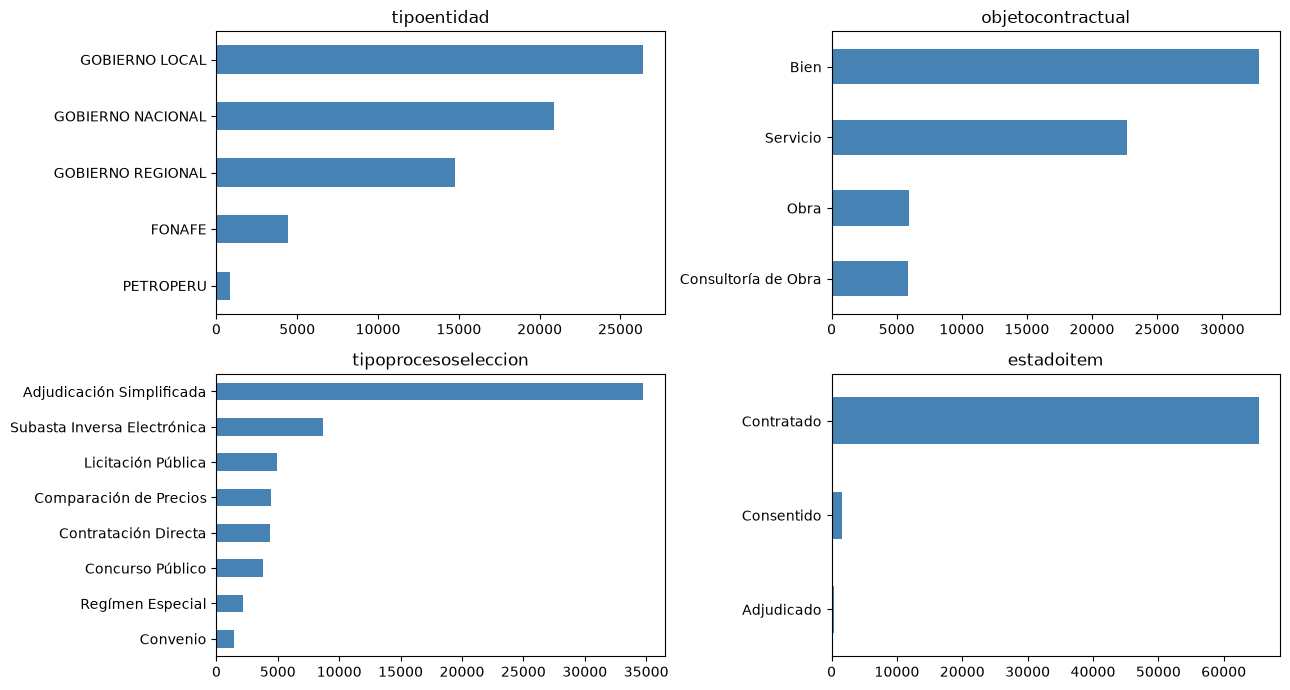

In [18]:
# Variables categóricas principales
cats = ['tipoentidad', 'objetocontractual', 'tipoprocesoseleccion', 'estadoitem']

fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for a, c in zip(ax.ravel(), cats):
    convocatorias[c].value_counts().head(8).sort_values().plot.barh(ax=a, color='steelblue')
    a.set_title(c)
    a.set_ylabel('')
plt.tight_layout()
plt.show()

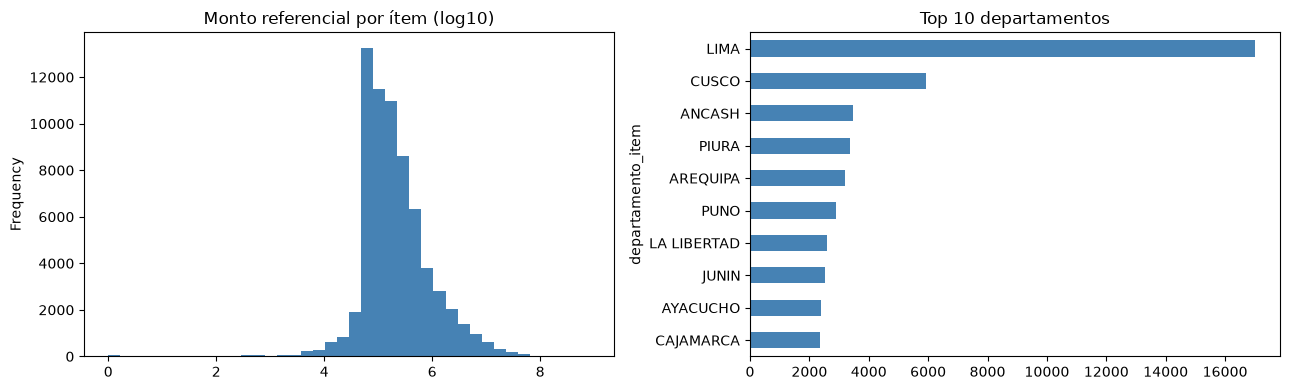

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

np.log10(convocatorias['monto_referencial_item'].clip(lower=1)).plot.hist(bins=40, ax=ax[0], color='steelblue')
ax[0].set_title('Monto referencial por ítem (log10)')

convocatorias['departamento_item'].value_counts().head(10).sort_values().plot.barh(ax=ax[1], color='steelblue')
ax[1].set_title('Top 10 departamentos')

plt.tight_layout()
plt.show()

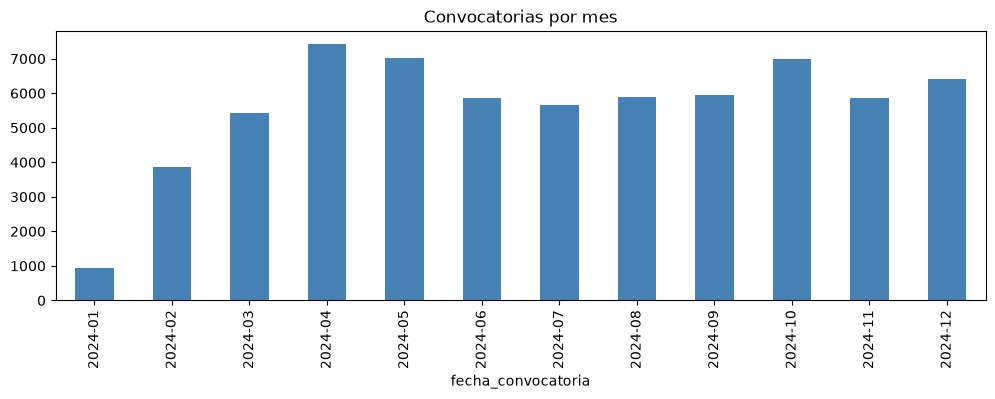

In [20]:
por_mes = convocatorias['fecha_convocatoria'].dt.to_period('M').value_counts().sort_index()
por_mes.plot.bar(figsize=(12, 3.5), color='steelblue', title='Convocatorias por mes')
plt.show()

In [21]:
print('Filas:                  ', len(convocatorias))
print('Convocatorias únicas:   ', convocatorias['codigoconvocatoria'].nunique())
print('Entidades únicas:       ', convocatorias['codigoentidad'].nunique())
print('Duplicados (convocatoria + ítem):', convocatorias.duplicated(['codigoconvocatoria', 'n_item']).sum())
print()
print('Montos referenciales iguales a 0:', (convocatorias['monto_referencial_item'] <= 0).sum())
print('Monedas:', convocatorias['moneda'].value_counts().to_dict())
print('Ítems con paquete = SI:', (convocatorias['paquete'] == 'SI').mean().round(3))

Filas:                   67291
Convocatorias únicas:    60611
Entidades únicas:        2737
Duplicados (convocatoria + ítem): 0

Montos referenciales iguales a 0: 75
Monedas: {'Soles': 65410, 'Dólar Norteamericano': 1399, 'Nuevos Soles': 322, 'Euro': 133, 'Libra Esterlina': 26, 'Dólar Canadiense': 1}
Ítems con paquete = SI: 0.156


In [22]:
# Estado de los ítems: ¿todos terminan en contrato?
convocatorias['estadoitem'].value_counts(normalize=True).round(3)

estadoitem
Contratado   0.97
Consentido   0.02
Adjudicado   0.01
Name: proportion, dtype: float64

### Qué vimos en convocatorias
- Tenemos **67,291 filas** (una por ítem) de **60,611 convocatorias** y 2,737 entidades. No hay duplicados por convocatoria + ítem.
- Los nulos están en `codigoitem` e `itemcubso` (~16%), en las fechas de bases y propuestas (36% y 11%) y en la ubicación (menos del 1%).
- Predominan los **bienes** (49%) y **servicios** (34%). El proceso más común es la **Adjudicación Simplificada** (52%), y el sistema de contratación más común es **Suma alzada** (74%).
- Por tipo de entidad: gobierno local (39%), nacional (31%) y regional (22%). Por ubicación, **Lima** concentra más del 25% de los ítems, seguido de Cusco, Ancash y Piura.
- Igual que en contratos, los montos son muy sesgados (mediana ~167 mil, máximo ~840 millones) y hay 75 ítems con monto referencial 0.
- El 97% de los ítems figura como "Contratado", así que `estadoitem` casi no distingue casos.
- Hay varias monedas, y `codigoitem` tiene un valor -1 que parece un código de "sin dato".
- `montoreferencial` es el monto del proceso completo y `monto_referencial_item` el del ítem: son distintos en ~15% de las filas.

## 3. Entidades contratantes

In [23]:
# Los CSV vienen separados por '|' y con codificación latin-1
entidades = pd.read_csv(RAW / 'entidades_contratantes' / 'entidades_contratantes.csv',
                        sep='|', encoding='latin-1', dtype=str)
print(entidades.shape)
entidades.head()

(3366, 9)


,RUC,NOMBRE_DE_ENTIDAD,DEPARTAMENTO,PROVINCIA,DISTRITO,CODIGO_SIAF,CODCONSUCODE,ESTADO,ULTIMAACTUALIZACION
0,20290898685,ACADEMIA DE LA MAGISTRATURA,LIMA,LIMA,JESUS MARIA,0014,1940,Activo,17/07/13
1,20556939781,AGENCIA DE COMPRAS DE LAS FUERZAS ARMADAS,LIMA,LIMA,JESUS MARIA,1545,201143,Activo,31/12/19
2,20380799643,AGENCIA DE PROMOCION DE LA INVERSION PRIVADA -...,LIMA,LIMA,SAN ISIDRO,1231,10001,Activo,25/09/15
3,20504915523,AGENCIA PERUANA DE COOPERACION INTERNACIONAL,LIMA,LIMA,LIMA,1089,200021,Activo,17/07/13
4,20514859559,AGROMERCADO,LIMA,LIMA,LINCE,1257,200189,Activo,22/04/25


In [24]:
print(entidades.isna().sum()[lambda s: s > 0])
print()
print('RUC duplicados:', entidades['RUC'].duplicated().sum())
print('Estado:', entidades['ESTADO'].value_counts().to_dict())

CODIGO_SIAF    351
dtype: int64

RUC duplicados: 0
Estado: {'Activo': 3259, 'Inactivo': 107}


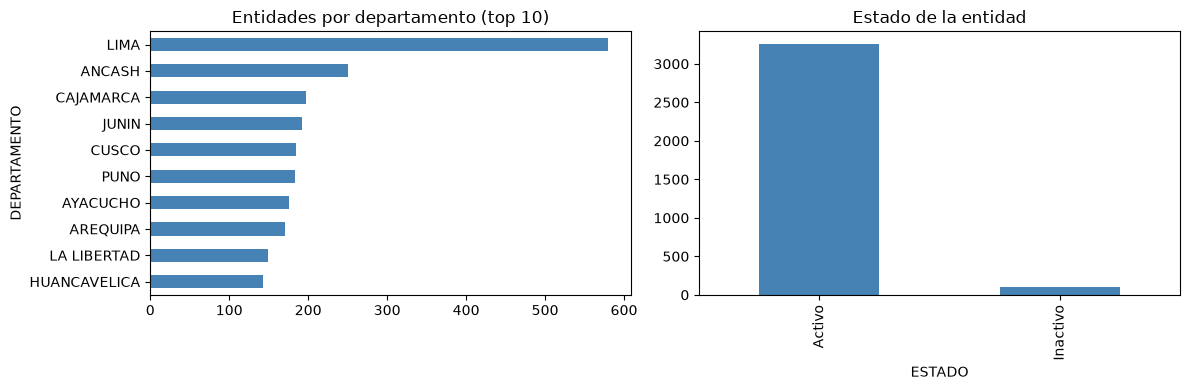

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
entidades['DEPARTAMENTO'].value_counts().head(10).sort_values().plot.barh(ax=ax[0], color='steelblue')
ax[0].set_title('Entidades por departamento (top 10)')
entidades['ESTADO'].value_counts().plot.bar(ax=ax[1], color='steelblue')
ax[1].set_title('Estado de la entidad')
plt.tight_layout()
plt.show()

### Qué vimos en entidades
- Es una tabla pequeña: **3,366 entidades**, sin RUC duplicados, así que sirve como tabla de consulta (una fila por entidad).
- Solo `CODIGO_SIAF` tiene nulos (~10%). El 97% de las entidades está **Activo**.
- Lima concentra la mayor cantidad de entidades (580), seguido de Ancash y Cajamarca.
- `ULTIMAACTUALIZACION` viene como texto con formato dd/mm/aa.

## 4. Sancionados (inhabilitaciones)

In [26]:
sancionados = pd.read_csv(RAW / 'sancionados' / 'sancionados.csv',
                          sep='|', encoding='latin-1', dtype=str)
print(sancionados.shape)
sancionados.head()

(9887, 8)


,FECHA_CORTE,RUC,NOMBRE_RAZONODENOMINACIONSOCIAL,FECHA_INICIO,FECHA_FIN,NUMERO_RESOLUCION,ID_MOTIVO_INFRACCION,DE_MOTIVO_INFRACCION
0,20261003,20100994128,CONSTRUCTORA DOS DE MAYO S.A.,19980806,NaN,074-1998-TL,12,RESCISION ADMINISTRATIVA DEL CONTRATO
1,20261003,20100247063,CEFOISA,19990218,NaN,008-1999-TC-S1,12,RESCISION ADMINISTRATIVA DEL CONTRATO
2,20261003,10092982349,VERA GUTIERREZ RODOLFO DAVID - INGENIERO,19961021,NaN,161-1996-TL,12,RESCISION ADMINISTRATIVA DEL CONTRATO
3,20261003,20113374650,SANTA GRACIELA S.A. CONTRATISTAS GENERALES,19951001,NaN,116-1995-TL,12,RESCISION ADMINISTRATIVA DEL CONTRATO
4,20261003,20124260460,NELLO PERALTA CONTRATISTAS GENERALES S.R.L.,19980123,NaN,193-1997-TL,12,RESCISION ADMINISTRATIVA DEL CONTRATO


In [27]:
print(sancionados.isna().sum()[lambda s: s > 0])
print()
print('Filas:', len(sancionados), '| RUC únicos:', sancionados['RUC'].nunique())
print('Largo del RUC:', sancionados['RUC'].str.len().value_counts().to_dict())

FECHA_FIN               1109
ID_MOTIVO_INFRACCION       1
DE_MOTIVO_INFRACCION       1
dtype: int64

Filas: 9887 | RUC únicos: 6276
Largo del RUC: {11: 9887}


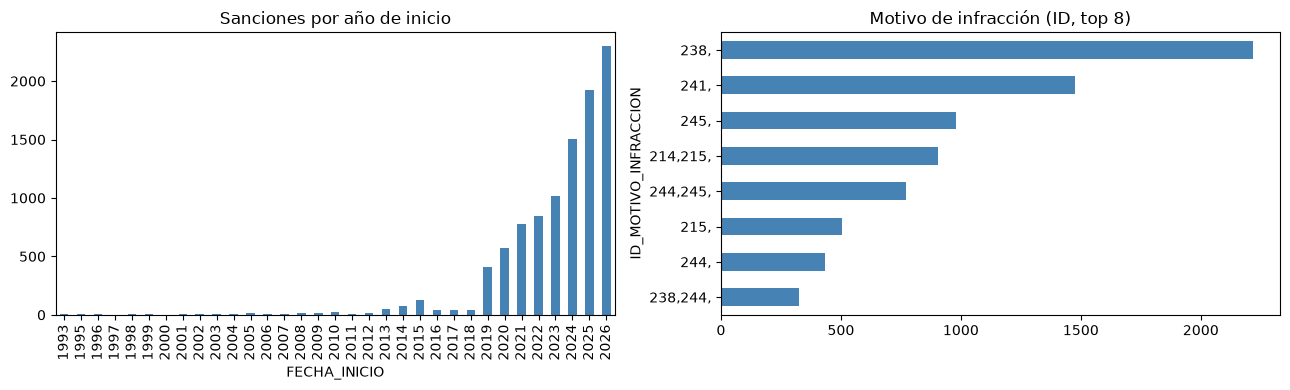

In [28]:
# Las fechas vienen como texto AAAAMMDD
sancionados['FECHA_INICIO'] = pd.to_datetime(sancionados['FECHA_INICIO'], format='%Y%m%d', errors='coerce')
sancionados['FECHA_FIN'] = pd.to_datetime(sancionados['FECHA_FIN'], format='%Y%m%d', errors='coerce')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sancionados['FECHA_INICIO'].dt.year.value_counts().sort_index().plot.bar(ax=ax[0], color='steelblue')
ax[0].set_title('Sanciones por año de inicio')

sancionados['ID_MOTIVO_INFRACCION'].value_counts().head(8).sort_values().plot.barh(ax=ax[1], color='steelblue')
ax[1].set_title('Motivo de infracción (ID, top 8)')
plt.tight_layout()
plt.show()

In [29]:
# El texto del motivo viene escrito de muchas formas distintas
print('Motivos distintos (texto):', sancionados['DE_MOTIVO_INFRACCION'].nunique())
print('Motivos distintos (ID):   ', sancionados['ID_MOTIVO_INFRACCION'].nunique())
sancionados['DE_MOTIVO_INFRACCION'].str[:80].value_counts().head(5)

Motivos distintos (texto): 120
Motivos distintos (ID):    143


DE_MOTIVO_INFRACCION
c) Contratar con el Estado estando impedido conforme a Ley.                         2219
f) Ocasionar que la Entidad resuelva el contrato, incluido Acuerdos Marco, siemp    1511
Presentar información inexacta a las Entidades, al Tribunal de Contrataciones de    1278
i) Presentar información inexacta a las Entidades, al Tribunal de Contrataciones    1257
j) Presentar documentos falsos o adulterados a las Entidades, al Tribunal de Con    1030
Name: count, dtype: int64

In [30]:
# Sanciones sin fecha de fin y sanciones aún vigentes a la fecha de corte
corte = pd.to_datetime(sancionados['FECHA_CORTE'].iloc[0], format='%Y%m%d')
print('Fecha de corte:', corte.date())
print('Sin fecha de fin:', sancionados['FECHA_FIN'].isna().sum())
print('Con fecha de fin posterior al corte:', (sancionados['FECHA_FIN'] > corte).sum())

Fecha de corte: 2026-10-03
Sin fecha de fin: 1109
Con fecha de fin posterior al corte: 2107


### Qué vimos en sancionados
- Hay **9,887 sanciones** de **6,276 proveedores** (un RUC puede tener varias sanciones). Todos los RUC tienen 11 dígitos.
- Las sanciones aumentan año a año (de ~410 en 2019 a ~2,300 en 2026, que aún no termina), así que el **tiempo** importa al cruzar con contratos.
- `FECHA_FIN` está vacía en 1,109 filas (sanciones sin fecha de término) y hay 43 casos con fecha de fin anterior a la de inicio.
- Los motivos vienen en texto muy variado (120 textos distintos, y varios son la misma infracción escrita de otra forma). `ID_MOTIVO_INFRACCION` a veces trae varios códigos juntos (por ejemplo `214,215,`).
- Todos los registros tienen la misma fecha de corte (2026-10-03).

## 5. Sancionados con multa

In [31]:
multas = pd.read_csv(RAW / 'sancionados' / 'sancionados_multa.csv',
                     sep='|', encoding='latin-1', dtype=str)
multas['MONTO'] = multas['MONTO'].astype(float)
multas['FECHA_INICIO'] = pd.to_datetime(multas['FECHA_INICIO'], format='%Y%m%d', errors='coerce')
print(multas.shape)
multas.head()

(4124, 9)


,FECHA_CORTE,RUC,NOMBRE_RAZONODENOMINACIONSOCIAL,FECHA_INICIO,FECHA_FIN,NUMERO_RESOLUCION,ID_MOTIVO_INFRACCION,DE_MOTIVO_INFRACCION,MONTO
0,20261003,10001108307,GONZALEZ VELA DANY ELENA,2023-01-03,20230503,4291-2022-TCE-S4,"237,",b) Incumplir injustificadamente con su obligac...,"23,000.00"
1,20261003,10001108307,GONZALEZ VELA DANY ELENA,2023-01-17,20230517,4513-2022-TCE-S2,"237,",b) Incumplir injustificadamente con su obligac...,"23,000.00"
2,20261003,10001229406,GRANDEZ RAMIREZ JUAN,2023-02-03,20230503,173-2023-TCE-S6,"237,",b) Incumplir injustificadamente con su obligac...,"24,750.00"
3,20261003,10001229406,GRANDEZ RAMIREZ JUAN,2023-02-28,20230528,662-2023-TCE-S5,"237,",b) Incumplir injustificadamente con su obligac...,"24,750.00"
4,20261003,10001229406,GRANDEZ RAMIREZ JUAN,2023-04-11,20230911,1502-2023-TCE-S5,"237,",b) Incumplir injustificadamente con su obligac...,"24,750.00"


In [32]:
print(multas.isna().sum()[lambda s: s > 0])
print()
print('Filas:', len(multas), '| RUC únicos:', multas['RUC'].nunique())
multas['MONTO'].describe()

FECHA_FIN               108
ID_MOTIVO_INFRACCION     18
DE_MOTIVO_INFRACCION     18
dtype: int64

Filas: 4124 | RUC únicos: 2904


count        4,124.00
mean       125,563.31
std        894,212.77
min              0.00
25%         23,000.00
50%         24,750.00
75%         25,750.00
max     20,000,000.00
Name: MONTO, dtype: float64

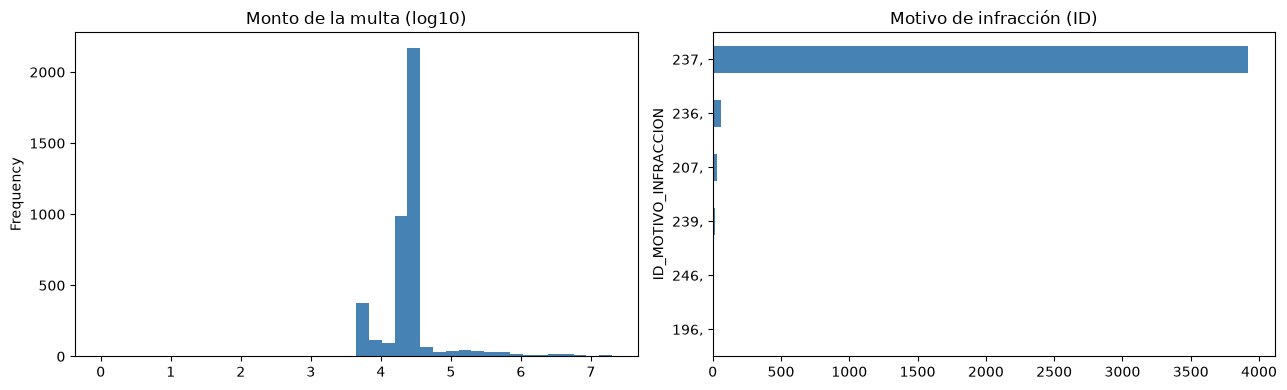

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
np.log10(multas['MONTO'].clip(lower=1)).plot.hist(bins=40, ax=ax[0], color='steelblue')
ax[0].set_title('Monto de la multa (log10)')

multas['ID_MOTIVO_INFRACCION'].value_counts().head(6).sort_values().plot.barh(ax=ax[1], color='steelblue')
ax[1].set_title('Motivo de infracción (ID)')
plt.tight_layout()
plt.show()

In [34]:
# ¿Los RUC multados también aparecen en la tabla de inhabilitaciones?
print('RUC en ambas tablas:', len(set(multas['RUC']) & set(sancionados['RUC'])))
print('Valores de ID_MOTIVO_INFRACCION:', multas['ID_MOTIVO_INFRACCION'].dropna().unique()[:6])

RUC en ambas tablas: 419
Valores de ID_MOTIVO_INFRACCION: <StringArray>
['237,', '236,', '246,', '248,', '240,', '239,']
Length: 6, dtype: str


### Qué vimos en multas
- Hay **4,124 multas** de **2,904 proveedores**. Solo 419 de esos RUC también aparecen en la tabla de inhabilitaciones.
- Los montos se concentran alrededor de 23 a 26 mil (mediana de 24,750), pero hay valores extremos de hasta 20 millones. Hay 3 multas con monto 0.
- El motivo es casi siempre el mismo (no perfeccionar el contrato, ID 237), y el código viene con una coma al final (`237,`).

## 6. RNP (Tribunal de Contrataciones)

Este archivo tiene extensión `.xls`, pero en realidad es una **página HTML** mal formada (con etiquetas sin cerrar), por eso `pd.read_excel` o `pd.read_html` no lo leen bien. Lo leemos con una función simple que separa filas y celdas. El archivo trae dos tablas: inhabilitaciones (definitivas y temporales) y multas.

In [35]:
def leer_rnp(ruta):
    texto = open(ruta, encoding='latin-1').read()
    inhab, multa = [], []
    seccion = None
    for fila in re.split(r'<tr[^>]*>', texto)[1:]:
        # Filas que solo indican la sección (Definitivo, Temporal, Multa)
        if 'colspan=13' in fila or 'colspan=14' in fila:
            seccion = html.unescape(re.sub(r'<[^>]+>', '', fila)).strip()
            continue
        celdas = [html.unescape(re.sub(r'<[^>]+>', ' ', c)).replace('\xa0', ' ').strip()
                  for c in re.split(r'<td[^>]*>', fila)[1:]]
        if celdas and celdas[0].isdigit():
            (inhab if len(celdas) == 11 else multa).append([seccion] + celdas)

    col_inhab = ['tipo', 'n', 'razon_social', 'ruc', 'resolucion', 'periodo', 'desde', 'hasta',
                 'infraccion', 'otra_infraccion', 'norma', 'estado']
    col_multa = ['tipo', 'n', 'razon_social', 'ruc', 'resolucion', 'fecha_resolucion', 'monto_multa',
                 'infraccion', 'periodo_suspension', 'desde', 'hasta', 'otra_infraccion', 'norma',
                 'verificacion_pago', 'estado']
    return pd.DataFrame(inhab, columns=col_inhab), pd.DataFrame(multa, columns=col_multa)

rnp_inhab, rnp_multa = leer_rnp(RAW / 'rnp' / 'Reporte_Sancionados_Tribunal_2026-10-11.xls')
print('Inhabilitaciones:', rnp_inhab.shape, '| Multas:', rnp_multa.shape)
rnp_inhab.head(3)

Inhabilitaciones: (11320, 12) | Multas: (6688, 15)


,tipo,n,razon_social,ruc,resolucion,periodo,desde,hasta,infraccion,otra_infraccion,norma,estado
0,Definitivo,1,CHALCO SULCA CARMELA,10408572661,8561-2026-TCP-S1,DEFINITIVO,06/10/2026,,- l) Presentar información inexacta a las enti...,,Ley Nº 32069,VIGENTE
1,Definitivo,2,JULIO CESAR QUIROZ AYASTA,10267226933,8602-2026-TCP-S6,DEFINITIVO,02/10/2026,,- m) Presentar documentos falsos o adulterados...,,Ley Nº 32069,VIGENTE
2,Definitivo,3,CHALCO SULCA CARMELA,10408572661,8477-2026-TCP-S1,DEFINITIVO,28/09/2026,,- j) Presentar documentos falsos o adulterados...,,TUO de la Ley N° 30225 - D.S N° 082-2019-E.F,VIGENTE


In [36]:
rnp_multa.head(3)

,tipo,n,razon_social,ruc,resolucion,fecha_resolucion,monto_multa,infraccion,periodo_suspension,desde,hasta,otra_infraccion,norma,verificacion_pago,estado
0,Multa,1,SERVICIOS E INNOVACIONES CK S.A.C. - SEICK S.A.C.,20606824344,8659-2026-TCP-S5,14/09/2026,428167.24,- b) Incumplir injustificadamente con su oblig...,4 MESES,7/10/2026,07/02/2027,,TUO de la Ley N° 30225 - D.S N° 082-2019-E.F,,VIGENTE
1,Multa,2,PUMA ASOCIADOS SOCIEDAD COMERCIAL DE RESPONSAB...,20527848246,1992-2026-TCP-S5,27/02/2026,3611558.19,- b) Incumplir injustificadamente con su oblig...,3 MESES,27/08/2026,27/11/2026,,TUO de la Ley N° 30225 - D.S N° 082-2019-E.F,,VIGENTE
2,Multa,3,PUMA ASOCIADOS SOCIEDAD COMERCIAL DE RESPONSAB...,20527848246,6893-2026-TCP-S5,6/07/2026,6019263.65,- b) Incumplir injustificadamente con su oblig...,3 MESES,27/08/2026,27/11/2026,,TUO de la Ley N° 30225 - D.S N° 082-2019-E.F,,VIGENTE


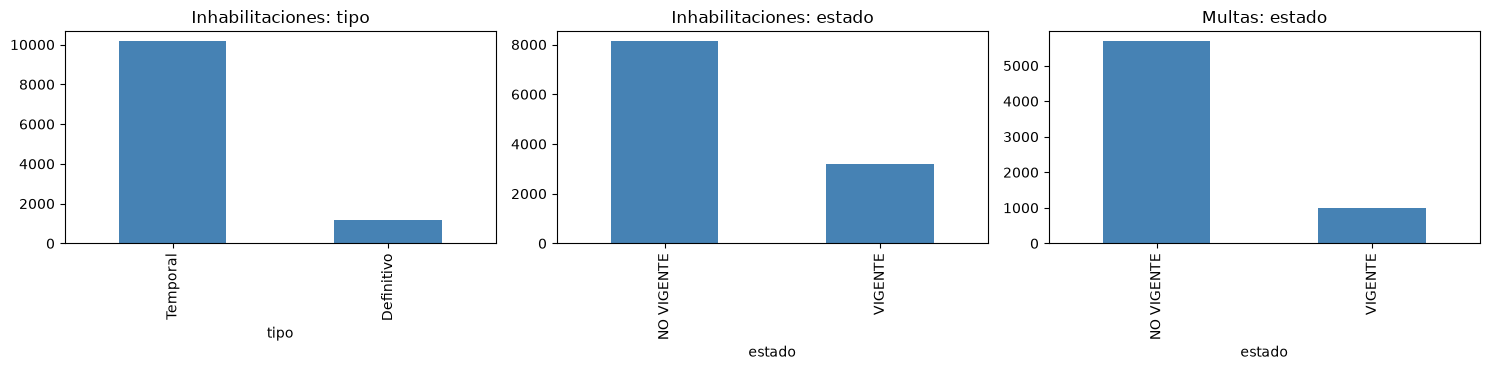

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
rnp_inhab['tipo'].value_counts().plot.bar(ax=ax[0], color='steelblue'); ax[0].set_title('Inhabilitaciones: tipo')
rnp_inhab['estado'].value_counts().plot.bar(ax=ax[1], color='steelblue'); ax[1].set_title('Inhabilitaciones: estado')
rnp_multa['estado'].value_counts().plot.bar(ax=ax[2], color='steelblue'); ax[2].set_title('Multas: estado')
plt.tight_layout()
plt.show()

In [38]:
rnp_multa['monto_multa'] = pd.to_numeric(rnp_multa['monto_multa'], errors='coerce')
print('RUC únicos inhabilitaciones:', rnp_inhab['ruc'].nunique(), '| multas:', rnp_multa['ruc'].nunique())
print('Largo del RUC:', rnp_inhab['ruc'].str.len().value_counts().to_dict())
print()
print('Periodos de inhabilitación más comunes:')
print(rnp_inhab['periodo'].value_counts().head(6))
print()
rnp_multa['monto_multa'].describe()

RUC únicos inhabilitaciones: 7135 | multas: 4718
Largo del RUC: {11: 11320}

Periodos de inhabilitación más comunes:
periodo
3 MESES       2000
4 MESES       1590
5 MESES       1027
DEFINITIVO    1001
36 MESES       797
24 MESES       724
Name: count, dtype: int64



count         6,688.00
mean        144,911.33
std       2,709,278.60
min               0.00
25%           8,994.00
50%          23,000.00
75%          24,750.00
max     157,966,799.00
Name: monto_multa, dtype: float64

### Qué vimos en el RNP
- Logramos leer **11,320 inhabilitaciones** (1,160 definitivas y 10,160 temporales) y **6,688 multas**, con ~7,100 y ~4,700 RUC distintos.
- Cerca del 28% de las inhabilitaciones está **VIGENTE** y el resto **NO VIGENTE**, lo que da una columna útil para saber si el proveedor estaba sancionado en un momento dado.
- Los periodos de inhabilitación son textos como "3 MESES" o "DEFINITIVO", y los montos de multa tienen valores extremos (hasta ~158 millones).
- Esta tabla parece repetir parte de la información de los CSV de sancionados, pero con más detalle (estado, periodo, norma). Falta verificar cuánto se solapan.

## 7. Relación entre las fuentes

Antes de pasar al preprocesamiento, revisamos rápido si las llaves de las tablas realmente se pueden cruzar. Usamos las muestras que ya cargamos (año 2024), así que los porcentajes son una referencia.

In [39]:
def pct(a, b):
    # % de valores de 'a' que aparecen en 'b'
    return round(a.isin(set(b)).mean() * 100, 1)

# RUC como texto para poder compararlos con los CSV
ruc_contratista = contratos['ruc_contratista'].astype(str)
ruc_pago = contratos['ruc_destinatario_pago'].astype(str)

resumen = pd.Series({
    'contratos -> convocatorias (codigoconvocatoria)':      pct(contratos['codigoconvocatoria'], convocatorias['codigoconvocatoria']),
    'contratos -> entidades (codigoentidad = CODCONSUCODE)': pct(contratos['codigoentidad'].astype(str), entidades['CODCONSUCODE']),
    'convocatorias -> entidades (entidad_ruc = RUC)':       pct(convocatorias['entidad_ruc'].astype(str), entidades['RUC']),
    'contratos -> sancionados (RUC contratista)':           pct(ruc_contratista, sancionados['RUC']),
    'contratos -> sancionados (RUC destinatario de pago)':  pct(ruc_pago, sancionados['RUC']),
    'contratos -> multas (RUC destinatario de pago)':       pct(ruc_pago, multas['RUC']),
    'contratos -> RNP (RUC destinatario de pago)':          pct(ruc_pago, rnp_inhab['ruc']),
}, name='% de filas con coincidencia')
resumen

contratos -> convocatorias (codigoconvocatoria)         100.00
contratos -> entidades (codigoentidad = CODCONSUCODE)   100.00
convocatorias -> entidades (entidad_ruc = RUC)          100.00
contratos -> sancionados (RUC contratista)                4.60
contratos -> sancionados (RUC destinatario de pago)       5.60
contratos -> multas (RUC destinatario de pago)            1.50
contratos -> RNP (RUC destinatario de pago)               6.80
Name: % de filas con coincidencia, dtype: float64

In [40]:
# Los RUC de 11 dígitos son los únicos que pueden coincidir con las tablas de sancionados
print('Contratos con ruc_contratista de 11 dígitos:     ', (ruc_contratista.str.len() == 11).mean().round(3))
print('Contratos con ruc_destinatario_pago de 11 dígitos:', (ruc_pago.str.len() == 11).mean().round(3))

Contratos con ruc_contratista de 11 dígitos:      0.601
Contratos con ruc_destinatario_pago de 11 dígitos: 1.0


### Qué vimos en la relación entre fuentes
- Las llaves entre **contratos, convocatorias y entidades se cruzan al 100%** en nuestras muestras.
- Con las tablas de sanciones el cruce es bajo (entre ~1.5% y ~7% de los contratos), lo cual es esperable: la mayoría de proveedores no está sancionada. Esto también indica que, si luego usamos las sanciones como objetivo, estará **muy desbalanceado**.
- Si cruzamos con `ruc_destinatario_pago` (siempre de 11 dígitos) en vez de `ruc_contratista`, evitamos perder el 40% de filas con RUC corto.

## 8. Resumen de preprocesamiento

**Antes de cruzar, por cada fuente:**

| Fuente | Qué debemos hacer |
|---|---|
| **Contratos** | Unificar nombres de columnas (2025-2026 vienen en mayúscula). Eliminar columnas constantes (`espublicado`, `monto_complementario`) y `tieneresolucion`/`urlcontrato` si no las usamos. Definir la unidad de análisis (contrato o ítem). Pasar los montos a una sola moneda y aplicar log a los montos. Revisar fechas raras (vigencia hasta 2047). Usar `ruc_destinatario_pago` como RUC de 11 dígitos. |
| **Convocatorias** | Unificar nombres de columnas y renombrar `COL_10` a `SECTOR / NIVEL DE GOBIERNO` (2025). Decidir qué hacer con nulos en `codigoitem`, `itemcubso`, fechas y ubicación. Revisar montos en 0 y `codigoitem` = -1. Codificar las categóricas (tipo de proceso, objeto, entidad, departamento). |
| **Entidades** | Convertir columnas a su tipo correcto (fechas dd/mm/aa). Dejarla como tabla de consulta por `CODCONSUCODE` / `RUC`. |
| **Sancionados** | Convertir fechas AAAAMMDD, tratar `FECHA_FIN` vacía como sanción sin término y revisar fechas inconsistentes. Limpiar y agrupar los motivos (separar `ID_MOTIVO_INFRACCION` con varios códigos). |
| **Multas** | Limpiar la coma final del ID de motivo, revisar montos 0 y extremos, y agrupar por RUC. |
| **RNP** | Usar la función de lectura del HTML, convertir fechas y montos, y quedarnos con `estado` y `periodo`. Comprobar el solapamiento con los CSV de sancionados para no duplicar información. |

**Para el cruce (notebook de preprocesamiento):**
1. Leer y juntar todos los años de contratos y de convocatorias (con nombres ya unificados).
2. Contratos + convocatorias por `codigoconvocatoria` y el ítem (`num_item` = `n_item`).
3. Agregar la información de la entidad por `codigoentidad` = `CODCONSUCODE` (o `entidad_ruc` = `RUC`).
4. Agregar las sanciones y multas por RUC (con `ruc_destinatario_pago`), **teniendo en cuenta las fechas**: para un contrato solo deberíamos usar sanciones que empezaron antes de su firma, para no filtrar información del futuro.
5. Como cada proveedor puede tener varias sanciones, resumirlas por RUC (cantidad, monto total, si estaba vigente) antes del cruce, para no multiplicar filas.

**Pendiente:** definir la variable objetivo del entrenamiento y cómo dividir los datos por tiempo (train/test), ya que las sanciones cambian con los años.